In [1]:
from PIL import Image
import numpy as np

In [2]:
a = np.asarray(Image.open('./beijing.jpg').convert('L')).astype('float')

In [3]:
depth = 10. 						# (0-100)
grad = np.gradient(a)				#取图像灰度的梯度值
grad_x, grad_y = grad 				#分别取横纵图像梯度值
grad_x = grad_x*depth/100.
grad_y = grad_y*depth/100.
A = np.sqrt(grad_x**2 + grad_y**2 + 1.)
uni_x = grad_x/A
uni_y = grad_y/A
uni_z = 1./A

In [4]:
vec_el = np.pi/2.2 					# 光源的俯视角度，弧度值
vec_az = np.pi/4. 					# 光源的方位角度，弧度值
dx = np.cos(vec_el)*np.cos(vec_az) 	#光源对x 轴的影响
dy = np.cos(vec_el)*np.sin(vec_az) 	#光源对y 轴的影响
dz = np.sin(vec_el) 				#光源对z 轴的影响

In [5]:
b = 255*(dx*uni_x + dy*uni_y + dz*uni_z) 	#光源归一化
b = b.clip(0,255)

In [6]:
im = Image.fromarray(b.astype('uint8')) 	#重构图像
im.save('./beijingHD.jpg')

In [7]:
im.show()

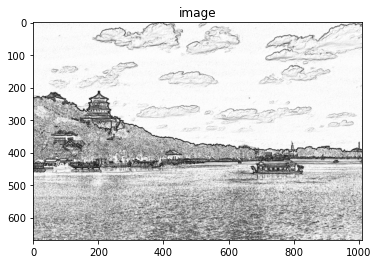

In [10]:
import matplotlib.pyplot as plt
plt.imshow(im,cmap='gray')
plt.axis('on')
plt.title('image')
plt.show()